# Cell-level errors and spatial neighborhood structure (§5.3)

Level 3: did segmentation preserve spatial relationships and local composition? Tissue neighborhoods are built from
cell–cell adjacency, so a spatial $k$-nearest-neighbor graph ($k{=}6$, the squidpy default) is constructed
independently from the expert cells and from each method's predicted cells (false positives included, as in real use)
under the same rule, and compared on edge recovery — among matched cells, and against *all* expert edges, where a
missed cell is charged for its lost relationships — on tumor–immune contacts, on per-cell neighborhood composition,
and on the region-level tumor–immune mixing score of Keren et al. (2018), the statistic behind the mixed /
compartmentalized architecture call.

Needs notebook 03 (`cells_expert.csv`, `cells_<run>.csv`, every seed). Writes `neighborhood_summary.csv` (mean over
seeds) and `neighborhood_summary_sd.csv` for notebook 05; the figures draw one seed.

In [1]:
# pick up edits to src/ without restarting the kernel
%load_ext autoreload
%autoreload 2
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from mxdata import DEFAULT_DATASET, load_config, load_regions, ingest, apply_qc_policy
from mxdata.data import LiveSource
from mxseg.evaluate import split_regions_of, read_prediction

# ---- edit here ---------------------------------------------------------------------------------------------------------
METHODS_ALL = ["unet_flows", "kodiakb_flows", "dinov3b_flows", "kodiakb_frozen", "dinov3b_frozen", "cellpose_ft",
               "cellpose", "cpdino", "instanseg", "sam3", "sam3_text", "sam2"]
SHOW_METHODS = ["cellpose", "cellpose_ft", "sam3", "dinov3b_frozen", "unet_flows", "kodiakb_flows"]
SEED = 0                                        # the seed drawn in every figure; every table pools the seeds (mean ± std)
TEST_SLIDE = "SLIDE-0236"                       # the paper's Slide 2: every §5 analysis runs on it; the other held-out slide (SLIDE-0233,
                                                # Slide 3) is scored in notebook 02's Slide-3 table from the stored per-region results
# METHODS_ALL: the paper's order (ViT-B rows, 10-epoch budget, 3 seeds); a method enters once its test-slide predictions exist.
# SHOW_METHODS: the image figures.
# ------------------------------------------------------------------------------------------------------------------------

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ANALYSIS = REPO / "outputs" / "analysis"
ANALYSIS.mkdir(parents=True, exist_ok=True)
PRED = REPO / "outputs" / "region" / "test"        # mxseg eval -b configs/baselines/<method>.yaml --split test --unit region --store-predictions
cfg = load_config(REPO / "configs" / "dataset.yaml")

LABEL = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B/16", "dinov3b_flows": "DINOv3 B/16", "kodiakb_frozen": "KODIAK B/16, frozen",
         "dinov3b_frozen": "DINOv3 B/16, frozen", "cellpose_ft": "Cellpose, adapted", "cellpose": "Cellpose-SAM, zero-shot",
         "cpdino": "Cellpose (DINOv3), zero-shot", "instanseg": "InstanSeg", "sam3": "SAM 3, exemplar", "sam3_text": "SAM 3, text",
         "sam2": "SAM 2.1, prototype",
         "kodiak_flows": "KODIAK S/16", "dinov3_flows": "DINOv3 S/16", "dinov3_frozen": "DINOv3 S/16, frozen", "kodiak_frozen": "KODIAK S/16, frozen"}
SHORT = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B", "dinov3b_flows": "DINOv3 B", "kodiakb_frozen": "KODIAK B frozen",
         "dinov3b_frozen": "DINOv3 B frozen", "cellpose_ft": "Cellpose adapted", "cellpose": "Cellpose-SAM 0-shot", "cpdino": "Cellpose-DINO 0-shot",
         "instanseg": "InstanSeg", "sam3": "SAM 3 exemplar", "sam3_text": "SAM 3 text", "sam2": "SAM 2.1",
         "kodiak_flows": "KODIAK S", "dinov3_flows": "DINOv3 S", "dinov3_frozen": "DINOv3 S frozen", "kodiak_frozen": "KODIAK S frozen"}
MCOLOR = {"unet_flows": "#2A78D6", "kodiakb_flows": "#7E1F2E", "dinov3b_flows": "#6E5314", "kodiakb_frozen": "#DF959E", "dinov3b_frozen": "#D3BF8C",
          "cellpose_ft": "#EB6834", "cellpose": "#8A8A8A", "cpdino": "#5A5A5A", "instanseg": "#3C9D9B",
          "sam3": "#1BAF7A", "sam3_text": "#E87BA4", "sam2": "#9A86E0",
          "kodiak_flows": "#C43E4E", "dinov3_flows": "#B08A2E", "dinov3_frozen": "#D3BF8C", "kodiak_frozen": "#DF959E"}   # the paper's swatches; frozen = tints
INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
PHENO_COLOR = {"Epithelial": "#2A78D6", "Immune": "#C43E4E", "Other": "#AEB2B8"}
CHIP = dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6)

def panel(ax, letter, dx=-0.04, dy=1.04):
    """Nature-style bold panel letter, outside the axes' top-left corner."""
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def chip(ax, text):
    """A short label inside an image panel (region, method) — never a sentence."""
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=7.2, fontweight="bold", color="white", va="top", bbox=CHIP)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def xgrid(ax):
    ax.grid(axis="x", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def barh_clean(ax):
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

def hex2rgb(h):
    return np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)])

def short(key):
    return key.split("_")[-1]

def norm01(img, lo=1, hi=99):
    a, b = np.percentile(img, (lo, hi))
    return np.clip((img - a) / max(b - a, 1e-6), 0, 1)

per_slide = split_regions_of(DEFAULT_DATASET, "test", cfg.slides)          # the protocol: held-out test slides, every region reviewed
assert TEST_SLIDE in per_slide, f"{TEST_SLIDE} is not a test slide of the split: {list(per_slide)}"
OTHER_TEST = [s for s in per_slide if s != TEST_SLIDE]                     # also held out (Slide 3): never pooled with TEST_SLIDE here
paths, mx, _ = ingest(TEST_SLIDE, None)
ids = sorted(per_slide[TEST_SLIDE])
regions = {r.region_id: r for r in load_regions(paths, ids, cfg.min_area_px)}
src = LiveSource(mx, list(regions.values()), cfg.markers, cfg.level)
TEST = {}                                          # key -> DAPI, labels (expert-flagged nuclei zeroed) and their ignore mask
for key in src.keys:
    rs = src.load(key)
    labels, ignore = apply_qc_policy(rs.labels, rs.flags, "ignore_wrong")
    r = regions[int(key.split("_R")[-1])]
    TEST[key] = dict(dapi=rs.image[0], labels=labels, ignore=ignore, region=r, has_qc=bool(r.has_qc))
PX_UM = float(mx.pixel_size_um or 0.325)

def runs_of(m):
    """The stored, complete runs of a method (every test region predicted): <method>_s<seed> for trained rows, the bare name for zero-shot rows."""
    names = sorted(d.name for d in PRED.glob(f"{m}_s[0-9]*") if d.is_dir()) or ([m] if (PRED / m).is_dir() else [])
    return [r for r in names if all((PRED / r / f"{k}.npz").is_file() for k in TEST)]
RUNS = {m: runs_of(m) for m in METHODS_ALL if runs_of(m)}
METHODS = list(RUNS)
RUN = {m: next((r for r in RUNS[m] if r.endswith(f"_s{SEED}")), RUNS[m][0]) for m in METHODS}   # the run drawn in the figures
if not METHODS:
    raise FileNotFoundError(f"no complete test-slide predictions under {PRED.relative_to(REPO)} — scripts/finetune_all.sh evaluates every run:  "
                            "mxseg eval -b configs/baselines/<method>.yaml --split test --unit region")
if len(METHODS) < len(METHODS_ALL):
    print("not evaluated yet, skipped:", ", ".join(LABEL[m] for m in METHODS_ALL if m not in METHODS))
SHOW = [m for m in SHOW_METHODS if m in METHODS]

def pred_of(run, key):
    """A stored instance map: ``run`` is a run name (<method>_s<seed>, or the bare name of a zero-shot row) or a method (its drawn run)."""
    return read_prediction(PRED / RUN.get(run, run) / f"{key}.npz")

def tag(key):
    return short(key) + ("*" if TEST[key]["has_qc"] else "")

def scalebar(ax, npx, um=50, color="white"):
    L = um / PX_UM
    x1, y = npx * 0.96, npx * 0.94
    ax.plot([x1 - L, x1], [y, y], color=color, lw=2.2, solid_capstyle="butt")
    ax.text(x1 - L / 2, y - npx * 0.025, f"{um} µm", color=color, ha="center", va="bottom", fontsize=7)

print(f"test slide {TEST_SLIDE}: {len(TEST)} regions ({', '.join(tag(k) for k in TEST)}; * = reviewed) | methods (seeds): "
      + ", ".join(f"{LABEL[m]} ({len(RUNS[m])})" for m in METHODS) + f" | figures draw seed {SEED}"
      + (f" | also held out, analysed separately: {', '.join(OTHER_TEST)}" if OTHER_TEST else ""))

/Users/marjan/Desktop/MedAI/NeurIPSWorkshop/src/mxseg/evaluate.py:184: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt = pd.read_csv(root / "patches.csv", dtype={"split": str, "group": str, "kind": str})


test slide SLIDE-0236: 6 regions (R01*, R02*, R03*, R04*, R05*, R06*; * = reviewed) | methods (seeds): U-Net (3), KODIAK B/16 (3), DINOv3 B/16 (3), KODIAK B/16, frozen (3), DINOv3 B/16, frozen (3), Cellpose, adapted (3), Cellpose-SAM, zero-shot (1), Cellpose (DINOv3), zero-shot (1), InstanSeg (1), SAM 3, exemplar (1), SAM 3, text (1), SAM 2.1, prototype (1) | figures draw seed 0 | also held out, analysed separately: SLIDE-0233


In [2]:
from mxseg.analysis import knn_edges, neighborhood_composition

CLASSES = ["Epithelial", "Immune", "Other"]
K_NN = 6
if not (ANALYSIS / "cells_expert.csv").is_file():
    raise FileNotFoundError("run notebook 03 first — no cells_expert.csv")
expert = pd.read_csv(ANALYSIS / "cells_expert.csv")
cells_run = {run: pd.read_csv(ANALYSIS / f"cells_{run}.csv") for m in METHODS for run in RUNS[m] if (ANALYSIS / f"cells_{run}.csv").is_file()}
RUNS = {m: [r for r in RUNS[m] if r in cells_run] for m in METHODS}
METHODS = [m for m in METHODS if RUNS[m]]
if not METHODS:
    raise FileNotFoundError("run notebook 03 first — no cells_<run>.csv tables under outputs/analysis")
RUN = {m: next((r for r in RUNS[m] if r.endswith(f"_s{SEED}")), RUNS[m][0]) for m in METHODS}
SHOW = [m for m in SHOW_METHODS if m in METHODS]
etab = expert.rename(columns={"id": "gt_id"})[["region", "gt_id", "cy", "cx"]]
for run in cells_run:                                                          # centroids of the matched predicted cells
    cells_run[run] = cells_run[run].merge(etab, on=["region", "gt_id"], suffixes=("", "_e"))
cells = {m: cells_run[RUN[m]] for m in METHODS}

def mixing_score(pheno, edges):
    """Keren et al. 2018: tumor-immune interactions / immune-immune interactions."""
    ti = sum(1 for i, j in edges if {pheno[i], pheno[j]} == {"Epithelial", "Immune"})
    ii = sum(1 for i, j in edges if pheno[i] == pheno[j] == "Immune")
    return ti / max(ii, 1)

rows, GRAPH = [], {}
for m in METHODS:
    for run in RUNS[m]:
        for key in TEST:
            e = expert[expert.region == key].reset_index(drop=True)
            ge = knn_edges(e.cy.values, e.cx.values, K_NN)
            ce = neighborhood_composition(list(e.pheno), ge, CLASSES)
            c = cells_run[run][cells_run[run].region == key].reset_index(drop=True)
            gp = knn_edges(c.cy.values, c.cx.values, K_NN)
            cp = neighborhood_composition(list(c.pheno_pred), gp, CLASSES)
            gt2row = {g: i for i, g in enumerate(e.id)}
            pr2row = {g: i for i, g in enumerate(c.gt_id)}
            common = [g for g in c.gt_id if g in gt2row]
            eall = {tuple(sorted((int(e.id[i]), int(e.id[j])))) for i, j in ge}
            eti = {tuple(sorted((int(e.id[i]), int(e.id[j])))) for i, j in ge if {e.pheno[i], e.pheno[j]} == {"Epithelial", "Immune"}}
            eset = {t for t in eall if t[0] in pr2row and t[1] in pr2row}
            pset = {tuple(sorted((int(c.gt_id[i]), int(c.gt_id[j])))) for i, j in gp if int(c.gt_id[i]) in gt2row and int(c.gt_id[j]) in gt2row}
            rows.append({"method": m, "run": run, "region": key,
                         "edge_recall_matched": len(eset & pset) / max(len(eset), 1),
                         "edge_recall_all": len(eset & pset) / max(len(eall), 1),
                         "edge_precision": len(eset & pset) / max(len(pset), 1),
                         "contact_recall_all": len(eti & pset) / max(len(eti), 1),
                         "ms_expert": mixing_score(list(e.pheno), ge), "ms_pred": mixing_score(list(c.pheno_pred), gp),
                         "comp_L1": np.mean([np.abs(ce[gt2row[g]] - cp[pr2row[g]]).sum() for g in common])})
            GRAPH[(run, key)] = dict(e=e, ce=ce, c=c, cp=cp, gt2row=gt2row)
res = pd.DataFrame(rows)
per_run = res.groupby(["method", "run"], sort=False).mean(numeric_only=True).reset_index()
num = [c_ for c_ in per_run.columns if c_ not in ("method", "run")]
summ = per_run.groupby("method", sort=False)[num].mean().loc[METHODS]                    # mean over seeds
summ_sd = per_run.groupby("method", sort=False)[num].std(ddof=0).loc[METHODS]
summ["seeds"] = per_run.groupby("method").run.count().loc[METHODS]
summ.to_csv(ANALYSIS / "neighborhood_summary.csv"); summ_sd.add_suffix("_sd").to_csv(ANALYSIS / "neighborhood_summary_sd.csv")
res.to_csv(ANALYSIS / "neighborhood_per_region.csv", index=False)
print("mean over seeds (std in neighborhood_summary_sd.csv):"); print(summ.round(3).rename(index=LABEL).to_string())

mean over seeds (std in neighborhood_summary_sd.csv):
                              edge_recall_matched  edge_recall_all  edge_precision  contact_recall_all  ms_expert  ms_pred  comp_L1  seeds
method                                                                                                                                    
U-Net                                       0.972            0.808           0.877               0.807      0.449    0.412    0.142      3
KODIAK B/16                                 0.976            0.780           0.862               0.752      0.449    0.417    0.149      3
DINOv3 B/16                                 0.973            0.765           0.852               0.741      0.449    0.426    0.161      3
KODIAK B/16, frozen                         0.975            0.669           0.803               0.627      0.449    0.423    0.188      3
DINOv3 B/16, frozen                         0.975            0.713           0.826               0.687      0.44

## 1. Relationship recovery

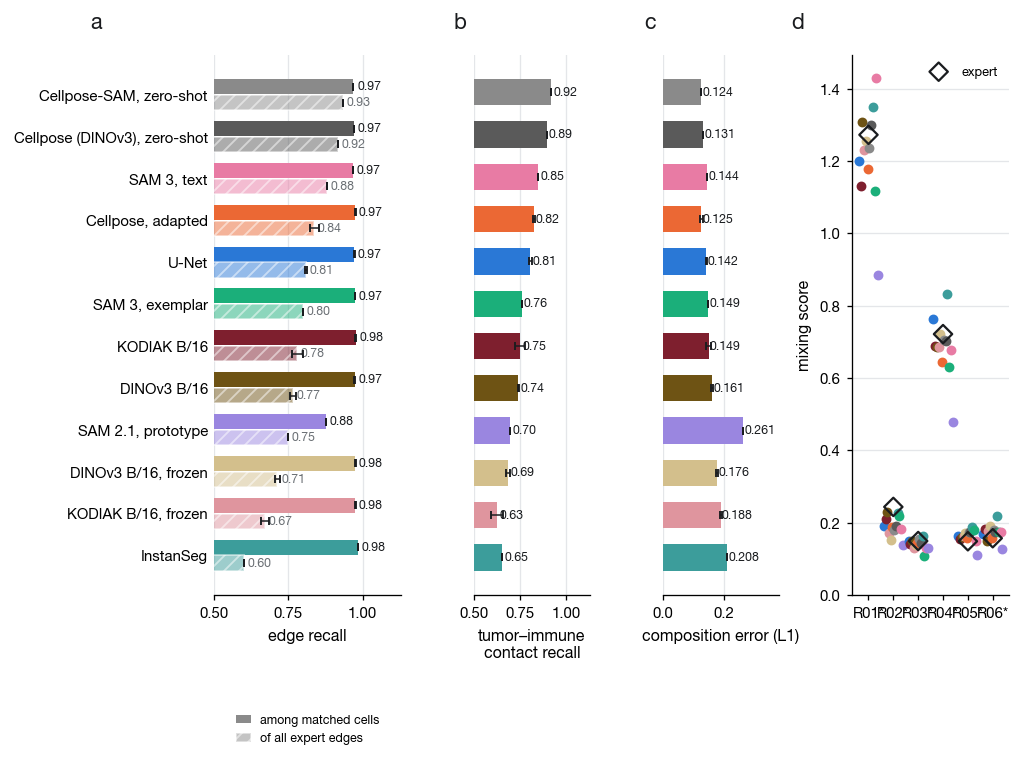

In [3]:
order = list(summ.sort_values("edge_recall_all", ascending=False).index)
y = np.arange(len(order))[::-1]
fig = plt.figure(figsize=(7.6, 0.6 + 0.3 * len(order) + 1.0))
gs = fig.add_gridspec(1, 4, width_ratios=[1.6, 1, 1, 1.35], wspace=0.5)
a = fig.add_subplot(gs[0])                                                     # a - edge recovery, two denominators
ek = dict(lw=0.8, capsize=2, ecolor=INK)
a.barh(y + 0.19, summ.loc[order, "edge_recall_matched"], 0.36, color=[MCOLOR[m] for m in order], zorder=3, label="among matched cells", xerr=summ_sd.loc[order, "edge_recall_matched"].fillna(0).values, error_kw=ek)
a.barh(y - 0.19, summ.loc[order, "edge_recall_all"], 0.36, color=[MCOLOR[m] for m in order], alpha=0.5, hatch="///", edgecolor="white", zorder=3, label="of all expert edges", xerr=summ_sd.loc[order, "edge_recall_all"].fillna(0).values, error_kw=ek)
for i, m in enumerate(order):
    a.text(summ.loc[m, "edge_recall_matched"] + 0.012, y[i] + 0.19, f"{summ.loc[m, 'edge_recall_matched']:.2f}", va="center", fontsize=6.6, color=INK)
    a.text(summ.loc[m, "edge_recall_all"] + 0.012, y[i] - 0.19, f"{summ.loc[m, 'edge_recall_all']:.2f}", va="center", fontsize=6.6, color=MUTED)
a.set_yticks(y, [LABEL[m] for m in order]); a.set_xlim(0.5, 1.13); a.set_xticks([0.5, 0.75, 1.0]); a.set_xlabel("edge recall")
a.legend(fontsize=6.6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1, handlelength=1.2)
xgrid(a); barh_clean(a)
panel(a, "a", dx=-0.6)
b = fig.add_subplot(gs[1])                                                     # b - tumor-immune contacts
b.barh(y, summ.loc[order, "contact_recall_all"], color=[MCOLOR[m] for m in order], height=0.62, zorder=3, xerr=summ_sd.loc[order, "contact_recall_all"].fillna(0).values, error_kw=ek)
for i, m in enumerate(order):
    b.text(summ.loc[m, "contact_recall_all"] + 0.012, y[i], f"{summ.loc[m, 'contact_recall_all']:.2f}", va="center", fontsize=6.6, color=INK)
b.set_yticks([]); b.set_xlim(0.5, 1.13); b.set_xticks([0.5, 0.75, 1.0]); b.set_xlabel("tumor–immune\ncontact recall")
xgrid(b); barh_clean(b)
panel(b, "b", dx=-0.06)
c = fig.add_subplot(gs[2])                                                     # c - composition error
c.barh(y, summ.loc[order, "comp_L1"], color=[MCOLOR[m] for m in order], height=0.62, zorder=3, xerr=summ_sd.loc[order, "comp_L1"].fillna(0).values, error_kw=ek)
for i, m in enumerate(order):
    c.text(summ.loc[m, "comp_L1"] + 0.004, y[i], f"{summ.loc[m, 'comp_L1']:.3f}", va="center", fontsize=6.6, color=INK)
c.set_yticks([]); c.set_xlim(0, summ.comp_L1.max() * 1.45); c.set_xlabel("composition error (L1)")
xgrid(c); barh_clean(c)
panel(c, "c", dx=-0.06)
d = fig.add_subplot(gs[3])                                                     # d - mixing score per region
keys = list(TEST)
for i, key in enumerate(keys):
    r = res[res.region == key]
    for j, m in enumerate(METHODS):
        d.scatter(i + 0.07 * (j - (len(METHODS) - 1) / 2), r[(r.method == m) & (r.run == RUN[m])].ms_pred, color=MCOLOR[m], s=18, zorder=3)
    d.scatter(i, r.ms_expert.iloc[0], marker="D", facecolor="none", edgecolor=INK, lw=1.2, s=48, zorder=4, label="expert" if i == 0 else None)
d.set_xticks(range(len(keys)), [tag(k) for k in keys]); d.set_ylabel("mixing score"); d.set_ylim(0)
d.legend(fontsize=6.8, loc="upper right")
ygrid(d)
panel(d, "d", dx=-0.3)
plt.show()

**Figure 1 — Do relationships survive?** (a) Recall of expert $k$NN edges ($k{=}6$) among matched cells (solid: graph
fidelity where both endpoints exist) and against all expert edges (hatched: a missed cell loses its relationships —
the stricter denominator, and the one that separates methods). (b) Recall of tumor–immune contacts, the edges that
carry the mixing statistic. (c) Mean per-cell neighborhood-composition error (L1 between expert-graph and
predicted-graph lineage fractions), the quantity niche discovery consumes. (d) Keren's mixing score per region from
each method's graph (dots) against the expert graph (diamond): the architecture call — mixed versus
compartmentalized — is the same under every segmentation.

## 2. Where neighborhoods change

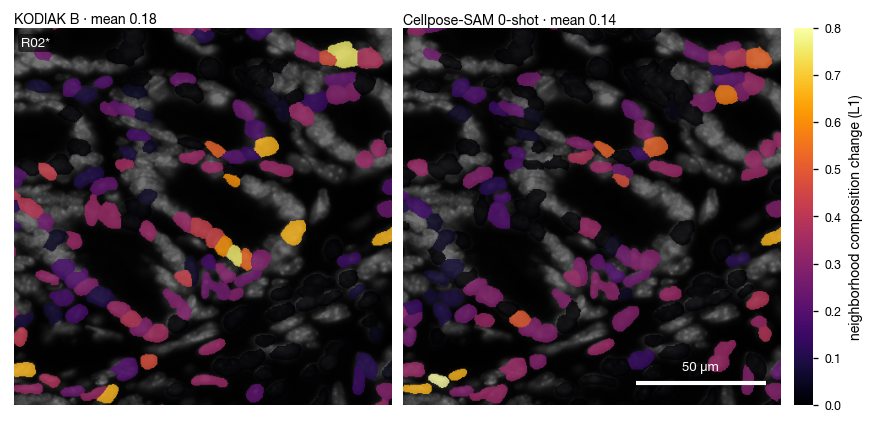

In [4]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors

key, (y0, x0), CROP = f"{TEST_SLIDE}_R02", (200, 300), 448
MAPS = list(dict.fromkeys([SHOW[-1], SHOW[0]])) if SHOW else METHODS[:2]      # the strongest and the noisiest of the shown methods
T = TEST[key]
norm = mcolors.Normalize(vmin=0, vmax=0.8)
cmap = plt.get_cmap("inferno")
fig, axes = plt.subplots(1, len(MAPS), figsize=(7.6, 7.6 / max(len(MAPS), 2) * 0.92 + 0.3), squeeze=False)
fig.subplots_adjust(left=0.005, right=0.9, top=0.94, bottom=0.02, wspace=0.03)
for a, m in zip(axes[0], MAPS):
    G = GRAPH[(RUN[m], key)]
    err = {int(g): float(np.abs(G["ce"][G["gt2row"][g]] - G["cp"][i]).sum()) for i, g in enumerate(G["c"].gt_id) if g in G["gt2row"]}
    lut = np.zeros((int(T["labels"].max()) + 1, 3)); has = np.zeros(int(T["labels"].max()) + 1, bool)
    for g, v in err.items():
        lut[g], has[g] = cmap(norm(v))[:3], True
    base = np.repeat((norm01(T["dapi"]) * 0.45)[..., None], 3, -1)
    L = T["labels"]
    mk = has[L]; base[mk] = 0.2 * base[mk] + 0.8 * lut[L[mk]]
    a.imshow(base[y0:y0 + CROP, x0:x0 + CROP]); a.set_axis_off()
    a.set_title(f"{SHORT[m]} · mean {np.mean(list(err.values())):.2f}", fontsize=7.5, pad=2)
chip(axes[0, 0], tag(key))
scalebar(axes[0, -1], CROP)
cb = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=list(axes[0]), shrink=0.8, pad=0.015)
cb.set_label("neighborhood composition change (L1)", fontsize=7.5); cb.ax.tick_params(labelsize=6.5); cb.outline.set_visible(False)
plt.show()

**Figure 2 — Neighborhood disruption on the tissue.** A 448² crop of region R2 of the test slide with every matched cell
colored by how much its neighborhood composition changed between the expert graph and the method's graph: dark cells
keep their neighborhood, bright cells have their local composition rewritten by segmentation errors nearby.

---
**References.** Palla et al., *Squidpy*, Nature Methods 2022 — $k$NN cell-graph construction. Keren et al., *A
Structured Tumor-Immune Microenvironment in Triple Negative Breast Cancer Revealed by Multiplexed Ion Beam Imaging*,
Cell 2018 — the mixing score and the architecture archetypes.